# P-02: PAH binding and reporter model results

**Task:** Calculate binding, reporter and competition outputs from the source model parameters.

**Inputs:** Parameter JSON and three documentary source model scripts.

**Motivation:** Explain the behaviour of the existing equations.

**Goal:** Export binding curves, reporter accumulation and mixture occupancy.

**Prediction:** Half occupancy occurs at free ligand = Kd; fixed competitors shift the pyrene occupancy curve to higher concentrations.

In [1]:
from pathlib import Path
import hashlib, json, platform, sys
from importlib.metadata import version
import numpy as np
import pandas as pd
import matplotlib
import matplotlib.pyplot as plt
from IPython.display import display, Markdown

from scipy.integrate import solve_ivp
TASK_ID = "P-02"

PROJECT_ROOT = next((p for p in [Path.cwd().resolve(), *Path.cwd().resolve().parents]
                     if (p / "data/input").is_dir() and (p / "tasks").is_dir()), None)
if PROJECT_ROOT is None:
    raise FileNotFoundError("Start Jupyter inside the project folder.")
INPUT = PROJECT_ROOT / "data/input"
OUTPUT = PROJECT_ROOT / "data/output" / TASK_ID
OUTPUT.mkdir(parents=True, exist_ok=True)
BLUE, ORANGE = "#0072B2", "#E69F00"
plt.rcParams.update({"font.family": "sans-serif", "font.size": 9,
                     "axes.spines.top": False, "axes.spines.right": False,
                     "savefig.dpi": 300})

ASSUMPTIONS_FILE = "P02_source_assumptions.json"
SOURCE_FILES = ["P02_model1_binding.py", "P02_model2_reporter.py", "P02_model3_competition.py"]
ALL_INPUTS = [ASSUMPTIONS_FILE] + SOURCE_FILES
FREE_LIGAND_NM = np.logspace(-2, 6, 240)
REPORTER_TIMES_MIN = np.linspace(0, 1440, 1441)
INITIAL_STATE = [0.01, 0.0, 0.0, 0.0]
COMMIT = "3539358236841e3f95f3e9efdc6d954fe1a1eca2"
SOURCE_URL = f"https://github.com/Raminyazdani/igem-saarland-2026-docking-comparison/tree/{COMMIT}/tools/autodock-vina/md/models"


## Materials and methods: binding

For one site, occupancy is θ=L/(Kd+L). Set koff=kon·Kd. The time to 95% approach from zero occupancy is -ln(0.05)/[kon·(L+Kd)]. The source parameter file defines the scenarios.

**Scope and working assumptions.** Affinities, concentrations and rates are fixed source-assigned parameters. The calculations assume one site, fixed free ligand, mutually exclusive competition and no depletion. The reporter represents an E. coli CFP/YFP model. Results are numerical consequences of these equations and parameters, rather than fitted measurements of yeast or cadmium performance.

In [2]:
assumptions = json.loads((INPUT / ASSUMPTIONS_FILE).read_text(encoding="utf-8"))
source_hashes = {name: hashlib.sha256((INPUT / name).read_bytes()).hexdigest() for name in ALL_INPUTS}
binding_rows, kinetic_rows = [], []
kon = assumptions["model1"]["kon_nM_inv_s_inv"]
for kd in assumptions["model1"]["Kd_grid_nM"]:
    occupancy = FREE_LIGAND_NM / (kd + FREE_LIGAND_NM)
    binding_rows.extend({"free_ligand_nM": l, "assumed_Kd_nM": kd, "occupancy": th} for l, th in zip(FREE_LIGAND_NM, occupancy))
    for ligand_nm in [1.0, 100.0]:
        kinetic_rows.append({"assumed_Kd_nM": kd, "free_ligand_nM": ligand_nm,
            "t95_min": -np.log(0.05) / (kon * (ligand_nm + kd)) / 60})
binding, kinetics = pd.DataFrame(binding_rows), pd.DataFrame(kinetic_rows)
binding.to_csv(OUTPUT / "binding_curve_plot_data.csv", index=False)
kinetics.to_csv(OUTPUT / "binding_kinetics.csv", index=False)
# A long table keeps every assigned parameter visible in the PDF.
parameter_table = pd.json_normalize(assumptions, sep=".").T.reset_index()
parameter_table.columns = ["Parameter", "Assumed value"]
parameter_table["Input data"] = ASSUMPTIONS_FILE
parameter_table["Finished without more wet-lab data?"] = "Yes: conditional model"
display(parameter_table)
parameter_table.to_csv(OUTPUT / "assumed_parameters.csv", index=False)


,Parameter,Assumed value,Input data,Finished without more wet-lab data?
0,model1.Kd_grid_nM,"[1.0, 10.0, 100.0, 1000.0, 10000.0]",P02_source_assumptions.json,Yes: conditional model
1,model1.kon_nM_inv_s_inv,0.00001,P02_source_assumptions.json,Yes: conditional model
2,model2.Kd_nM.fluoranthene,100.0,P02_source_assumptions.json,Yes: conditional model
3,model2.Kd_nM.pyrene,300.0,P02_source_assumptions.json,Yes: conditional model
4,model2.Kd_nM.phenanthrene,500.0,P02_source_assumptions.json,Yes: conditional model
5,model2.Kd_nM.naphthalene,5000.0,P02_source_assumptions.json,Yes: conditional model
6,model2.R_free,1.0,P02_source_assumptions.json,Yes: conditional model
7,model2.R_bound,1.6,P02_source_assumptions.json,Yes: conditional model
8,model2.parameters.alpha_arbitrary_per_min,1.0,P02_source_assumptions.json,Yes: conditional model
9,model2.parameters.mRNA_half_life_min,5,P02_source_assumptions.json,Yes: conditional model


## Materials and methods: reporter accumulation

N is growth relative to carrying capacity; m, I and S are mRNA, immature and mature reporter in model units.

μ=μ₀(1−N); a=α[basal+(1−basal)μ/μ₀]. The ODEs are N′=μN; m′=a−δₘm; I′=βm−(kmat+μ+δₚ)I; S′=kmat·I−(μ+δₚ)S. Half-times define the decay rates. Integrate 0–1440 min with DOP853, relative tolerance 10⁻⁸ and absolute tolerance 10⁻¹⁰. Report the maximum on the sampled one-minute grid. The ideal ratio is Rfree+(Rbound−Rfree)L/(Kd+L).

In [3]:
model2, p = assumptions["model2"], assumptions["model2"]["parameters"]
delta_m = np.log(2) / p["mRNA_half_life_min"]
kmat = np.log(2) / p["maturation_half_life_min"]
mu0 = np.log(2) / p["doubling_time_min"]
delta_p = np.log(2) / p["turnover_half_life_min"]
def reporter_rhs(time, state):
    # Growth-dependent production, maturation, dilution and turnover.
    n, mrna, immature, mature = state
    mu = mu0 * (1 - n)
    production = p["alpha_arbitrary_per_min"] * (p["stationary_promoter_floor"] + (1 - p["stationary_promoter_floor"]) * mu / mu0)
    return [mu * n, production - delta_m * mrna,
            p["translation_per_mRNA_per_min"] * mrna - (kmat + mu + delta_p) * immature,
            kmat * immature - (mu + delta_p) * mature]
solution = solve_ivp(reporter_rhs, (0, 1440), INITIAL_STATE, t_eval=REPORTER_TIMES_MIN,
                     method="DOP853", rtol=1e-8, atol=1e-10)
if not solution.success:
    raise RuntimeError(solution.message)
reporter = pd.DataFrame(solution.y.T, columns=["growth_fraction", "mrna_model_units", "immature_model_units", "mature_model_units"])
reporter.insert(0, "time_min", solution.t)
peak_index = reporter.mature_model_units.idxmax()
peak_time_h = reporter.loc[peak_index, "time_min"] / 60
reporter["mature_fraction_of_model_max"] = reporter.mature_model_units / reporter.mature_model_units.max()
ratio_rows = []
for ligand, kd in model2["Kd_nM"].items():
    for concentration in [20.0, 100.0, 1000.0]:
        ratio_rows.append({"ligand": ligand, "free_ligand_nM": concentration, "assumed_Kd_nM": kd,
            "ideal_ratio": model2["R_free"] + (model2["R_bound"] - model2["R_free"]) * concentration / (kd + concentration)})
ratios = pd.DataFrame(ratio_rows)
reporter.to_csv(OUTPUT / "reporter_plot_data.csv", index=False)
ratios.to_csv(OUTPUT / "ideal_reporter_ratios.csv", index=False)


## Materials and methods: competition

Ligands compete for one mutually exclusive site at fixed free concentrations. For ligand i, θᵢ=(Lᵢ/Kdᵢ)/(1+ΣLⱼ/Kdⱼ); the unbound fraction is 1/(1+ΣLⱼ/Kdⱼ). The apparent pyrene half-site concentration under fixed competitors is Kd,pyrene·(1+Σcompetitors Lⱼ/Kdⱼ).

In [4]:
model3 = assumptions["model3"]
kd = pd.Series(model3["assumed_Kd_nM"], dtype=float)
concentration = pd.Series(model3["assumed_free_concentration_nM"], dtype=float).reindex(kd.index)
assert (kd > 0).all() and (concentration >= 0).all()
weight = concentration / kd
mixture = pd.DataFrame({"assumed_Kd_nM": kd, "assumed_free_ligand_nM": concentration,
                        "competition_weight": weight, "site_fraction": weight / (1 + weight.sum())})
mixture.index.name = "ligand"
unbound = 1 / (1 + weight.sum())
competitor_weight = weight.drop("pyrene").sum()
apparent_half_nM = kd["pyrene"] * (1 + competitor_weight)
competition = pd.DataFrame({"free_pyrene_nM": FREE_LIGAND_NM,
    "pyrene_alone": FREE_LIGAND_NM / (kd["pyrene"] + FREE_LIGAND_NM),
    "fixed_competitors": FREE_LIGAND_NM / (apparent_half_nM + FREE_LIGAND_NM)})
mixture.to_csv(OUTPUT / "mixture_plot_data.csv")
competition.to_csv(OUTPUT / "pyrene_competition_curves.csv", index=False)


## Results

The figures and CSV files give the outputs of each model. Reporter accumulation is divided by its sampled maximum for plotting.

,assumed_Kd_nM,free_ligand_nM,t95_min,Input data,Finished without more wet-lab data?
0,1.0,1.0,2496.4436,Model 1 assumptions,Yes: conditional model
1,1.0,100.0,49.4345,Model 1 assumptions,Yes: conditional model
2,10.0,1.0,453.8988,Model 1 assumptions,Yes: conditional model
3,10.0,100.0,45.3899,Model 1 assumptions,Yes: conditional model
4,100.0,1.0,49.4345,Model 1 assumptions,Yes: conditional model
5,100.0,100.0,24.9644,Model 1 assumptions,Yes: conditional model
6,1000.0,1.0,4.9879,Model 1 assumptions,Yes: conditional model
7,1000.0,100.0,4.5390,Model 1 assumptions,Yes: conditional model
8,10000.0,1.0,0.4992,Model 1 assumptions,Yes: conditional model
9,10000.0,100.0,0.4943,Model 1 assumptions,Yes: conditional model


,ligand,free_ligand_nM,assumed_Kd_nM,ideal_ratio,Input data,Finished without more wet-lab data?
0,fluoranthene,20.0,100.0,1.1000,Model 2 assumptions,Yes: conditional model
1,fluoranthene,100.0,100.0,1.3000,Model 2 assumptions,Yes: conditional model
2,fluoranthene,1000.0,100.0,1.5455,Model 2 assumptions,Yes: conditional model
3,pyrene,20.0,300.0,1.0375,Model 2 assumptions,Yes: conditional model
4,pyrene,100.0,300.0,1.1500,Model 2 assumptions,Yes: conditional model
5,pyrene,1000.0,300.0,1.4615,Model 2 assumptions,Yes: conditional model
6,phenanthrene,20.0,500.0,1.0231,Model 2 assumptions,Yes: conditional model
7,phenanthrene,100.0,500.0,1.1000,Model 2 assumptions,Yes: conditional model
8,phenanthrene,1000.0,500.0,1.4000,Model 2 assumptions,Yes: conditional model
9,naphthalene,20.0,5000.0,1.0024,Model 2 assumptions,Yes: conditional model


,assumed_Kd_nM,assumed_free_ligand_nM,competition_weight,site_fraction,Input data,Finished without more wet-lab data?
ligand,,,,,,
fluoranthene,100.0,20.0,0.20000,0.13565,Model 3 assumptions,Yes: conditional model
pyrene,300.0,20.0,0.06667,0.04522,Model 3 assumptions,Yes: conditional model
phenanthrene,500.0,50.0,0.10000,0.06783,Model 3 assumptions,Yes: conditional model
anthracene,1500.0,10.0,0.00667,0.00452,Model 3 assumptions,Yes: conditional model
naphthalene,5000.0,500.0,0.10000,0.06783,Model 3 assumptions,Yes: conditional model
glucose,1000000.0,1000.0,0.00100,0.00068,Model 3 assumptions,Yes: conditional model


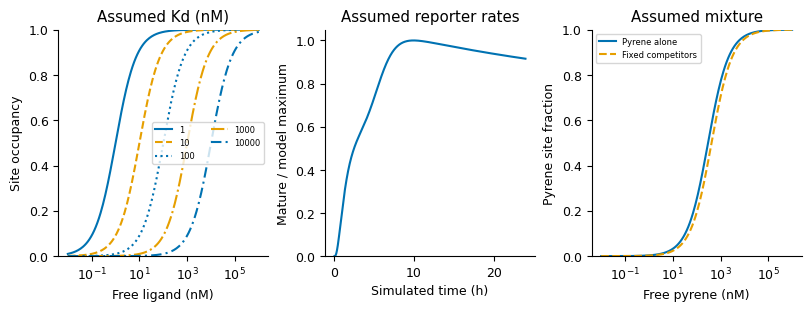

In [5]:
def result_view(table, input_data):
    return table.assign(**{"Input data": input_data, "Finished without more wet-lab data?": "Yes: conditional model"})
display(result_view(kinetics.round(4), "Model 1 assumptions"),
        result_view(ratios.round(4), "Model 2 assumptions"),
        result_view(mixture.round(5), "Model 3 assumptions"))
fig, axes = plt.subplots(1, 3, figsize=(8.0, 3.0), layout="constrained")
for index, (kd_value, group) in enumerate(binding.groupby("assumed_Kd_nM")):
    axes[0].semilogx(group.free_ligand_nM, group.occupancy, label=f"{kd_value:g}", color=[BLUE, ORANGE][index % 2], linestyle=["-", "--", ":", "-.", (0, (5, 2, 1, 2))][index])
axes[0].set(xlabel="Free ligand (nM)", ylabel="Site occupancy", ylim=(0, 1), title="Assumed Kd (nM)")
axes[0].legend(fontsize=6, ncol=2)
axes[1].plot(reporter.time_min / 60, reporter.mature_fraction_of_model_max, color=BLUE)
axes[1].set(xlabel="Simulated time (h)", ylabel="Mature / model maximum", ylim=(0, 1.05), title="Assumed reporter rates")
axes[2].semilogx(competition.free_pyrene_nM, competition.pyrene_alone, color=BLUE, label="Pyrene alone")
axes[2].semilogx(competition.free_pyrene_nM, competition.fixed_competitors, color=ORANGE, ls="--", label="Fixed competitors")
axes[2].set(xlabel="Free pyrene (nM)", ylabel="Pyrene site fraction", ylim=(0, 1), title="Assumed mixture")
axes[2].legend(fontsize=6)
fig.savefig(OUTPUT / "conditional_models.png", dpi=300, bbox_inches="tight")
fig.savefig(OUTPUT / "conditional_models.svg", bbox_inches="tight")
plt.show()
runtime = {name: version(name) for name in ["numpy", "pandas", "scipy", "matplotlib"]}
(OUTPUT / "source_manifest.json").write_text(json.dumps({"sha256": source_hashes,
    "source_commit": COMMIT, "python": sys.version, "platform": platform.platform(),
    "packages": runtime, "assumptions": assumptions}, indent=2), encoding="utf-8");

In [6]:
# The conclusion stays conditional on the explicitly assigned inputs.
t95 = float(kinetics[(kinetics.assumed_Kd_nM == 100) & (kinetics.free_ligand_nM == 100)].t95_min.iloc[0])
pyrene_ratio = float(ratios[(ratios.ligand == "pyrene") & (ratios.free_ligand_nM == 100)].ideal_ratio.iloc[0])
pyrene_fraction = float(mixture.loc["pyrene", "site_fraction"])
conclusion = ((f"At Kd = free ligand = 100 nM, the binding model gives t95 = {t95:.3f} min. "
              f"The reporter reaches its sampled maximum at {peak_time_h:.3f} simulated hours. "
              f"Fixed competitors shift pyrene half occupancy from {kd['pyrene']:.1f} to {apparent_half_nM:.1f} nM; "
              f"mixture pyrene occupancy is {pyrene_fraction:.5f} and the unbound fraction is {unbound:.5f}."))
table_rows = [["Binding: Kd=L=100 nM", "t95 (min)", round(t95, 4)], ["Reporter", "Sampled peak (simulated h)", round(peak_time_h, 4)],
              ["Pyrene at 100 nM", "Ideal ratio", round(pyrene_ratio, 4)], ["Assumed mixture", "Pyrene site fraction", round(pyrene_fraction, 6)],
              ["Assumed mixture", "Unbound fraction", round(float(unbound), 6)], ["Fixed competitors", "Pyrene half-site (nM)", round(float(apparent_half_nM), 4)]]
table_rows = [row + ["Stored assumed parameters", "Yes: conditional model"] for row in table_rows]
table_columns = ["Scenario", "Quantity", "Value", "Input data", "Finished without more wet-lab data?"]
display(pd.DataFrame(table_rows, columns=table_columns))
pd.DataFrame(table_rows, columns=table_columns).to_csv(OUTPUT / "scenario_summary.csv", index=False)
summary = {"title": "P-02: PAH binding and reporter model results", "question": "What follows from the project's existing assumed model inputs?",
    "materials": ["Stored source_assumptions.json; original model scripts preserved as inert equation/provenance records.", "No fitted parameters or new experimental data."],
    "methods": ["Analytical single-site occupancy and fixed-ligand approach to equilibrium.", "Source reporter ODE integrated by DOP853 (rtol 1e-8; atol 1e-10) on a one-minute output grid.", "Deterministic competitive occupancy at assigned free concentrations; no score-to-Kd conversion."],
    "results": [f"Model 1, Kd=L=100 nM: t95={t95:.4f} min.", f"Reporter sampled maximum: {peak_time_h:.4f} simulated h; ideal pyrene ratio at 100 nM={pyrene_ratio:.4f}.", f"Model 3 mixture: pyrene fraction={pyrene_fraction:.6f}, unbound={unbound:.6f}; competitor half-site={apparent_half_nM:.1f} nM."],
    "conclusion": conclusion,
    "limitations": [],
    "figures": [{"file": "conditional_models.png", "caption": "Conditional binding curves, reporter accumulation and pyrene competition under stored assumptions. All times are simulated; lines are not measured data."}],
    "references": [SOURCE_URL, "Stored source_assumptions.json: explicit source-derived parameter transcription; source hashes and complete parameters are in source_manifest.json."],
    "table": {"columns": table_columns, "rows": table_rows}}
summary["scope_and_assumptions"] = 'Affinities, concentrations and rates are fixed source-assigned parameters. The calculations assume one site, fixed free ligand, mutually exclusive competition and no depletion. The reporter represents an E. coli CFP/YFP model. Results are numerical consequences of these equations and parameters, rather than fitted measurements of yeast or cadmium performance.'
summary.pop("limitations", None)
(OUTPUT / "summary.json").write_text(json.dumps(summary, indent=2, ensure_ascii=False), encoding="utf-8")
display(Markdown("## Conclusion and interpretation\n\n" + conclusion))

,Scenario,Quantity,Value,Input data,Finished without more wet-lab data?
0,Binding: Kd=L=100 nM,t95 (min),24.964400,Stored assumed parameters,Yes: conditional model
1,Reporter,Sampled peak (simulated h),9.933300,Stored assumed parameters,Yes: conditional model
2,Pyrene at 100 nM,Ideal ratio,1.150000,Stored assumed parameters,Yes: conditional model
3,Assumed mixture,Pyrene site fraction,0.045218,Stored assumed parameters,Yes: conditional model
4,Assumed mixture,Unbound fraction,0.678273,Stored assumed parameters,Yes: conditional model
5,Fixed competitors,Pyrene half-site (nM),422.300000,Stored assumed parameters,Yes: conditional model


## Conclusion and interpretation

At Kd = free ligand = 100 nM, the binding model gives t95 = 24.964 min. The reporter reaches its sampled maximum at 9.933 simulated hours. Fixed competitors shift pyrene half occupancy from 300.0 to 422.3 nM; mixture pyrene occupancy is 0.04522 and the unbound fraction is 0.67827.